In [ ]:
%pip install gradio_client pillow matplotlib requests

In [18]:
import requests
import io
import time
import matplotlib.pyplot as plt
from PIL import Image
from my_secrets import HF_API
# Pega aquí tu token NUEVO (el anterior revócalo)
HF_TOKEN = HF_API
MODEL_ID = "stabilityai/stable-diffusion-xl-base-1.0"
API_URL = f"https://router.huggingface.co/hf-inference/models/{MODEL_ID}"
headers = {"Authorization": f"Bearer {HF_TOKEN}"}
print("Configuración lista.")
print(f"Modelo: {MODEL_ID}")

Configuración lista.
Modelo: stabilityai/stable-diffusion-xl-base-1.0


In [4]:
from gradio_client import Client
from PIL import Image

# Usamos el token para tener más cuota de GPU
try:
    client = Client("black-forest-labs/FLUX.1-schnell", token=HF_TOKEN)
except TypeError:
    # Versiones antiguas de gradio_client usan otro nombre
    client = Client("black-forest-labs/FLUX.1-schnell", hf_token=HF_TOKEN)

def generar_imagen(prompt, cfg=None, pasos=4, seed=42):
    try:
        ruta, seed_usada = client.predict(
            prompt=prompt,
            seed=seed,
            randomize_seed=False,
            width=512,
            height=512,
            num_inference_steps=pasos,
            api_name="/infer",
        )
        return Image.open(ruta)
    except Exception as e:
        print("Error al generar la imagen:", e)
        return None

Loaded as API: https://black-forest-labs-flux-1-schnell.hf.space


Generando imagen... (puede tardar 15–30 segundos)


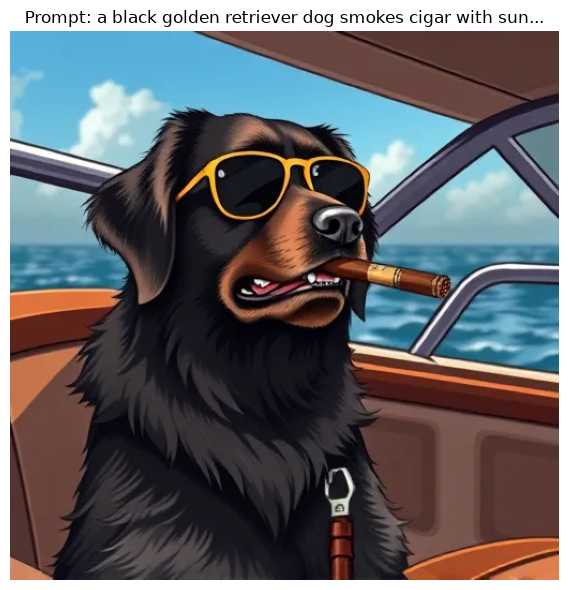

Imagen guardada como imagen_01.png


In [15]:
import matplotlib.pyplot as plt

mi_prompt = "a black golden retriever dog smokes cigar with sunglasses sitting in a yacht, anime, high quality"

print("Generando imagen... (puede tardar 15–30 segundos)")
imagen = generar_imagen(prompt=mi_prompt, pasos=4)

if imagen is not None:
    plt.figure(figsize=(6, 6))
    plt.imshow(imagen)
    plt.axis("off")
    plt.title(f"Prompt: {mi_prompt[:50]}...")
    plt.tight_layout()
    plt.show()

    imagen.save("imagen_01.png")
    print("Imagen guardada como imagen_01.png")
else:
    print("No se generó la imagen. Mira el mensaje de error de arriba.")